# 🎵 Segmentación del Catálogo Musical de Spotify y Recomendador por Similitud

**Autor:** Héctor Estéfano Gómez Vigo

---

Proyecto de analítica de datos sobre el *Spotify Tracks Dataset* (dataset público, ~114,000 registros originales; versión de referencia: [Hugging Face](https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset)). Objetivos:

1. **Segmentar el catálogo:** agrupar las pistas en perfiles sonoros diferenciados mediante aprendizaje no supervisado (**K-Means**), a partir de 9 características de audio.
2. **Visualizar en 2D:** reducir la dimensionalidad con **PCA** para observar la distribución de los perfiles y su solapamiento.
3. **Recomendar por similitud:** construir un recomendador **basado en contenido** que, dada una canción, localiza con **distancia coseno** las pistas más parecidas dentro de su mismo clúster.

**Técnicas:** K-Means · PCA · Coeficiente de Silhouette · Vecinos más cercanos (distancia coseno)

### 1. CARGA Y LECTURA DE DATOS
El archivo trae algunas filas mal formadas, que se omiten al leer (`on_bad_lines='skip'`). Se informa cuántos registros se leen para ser transparentes con esa pérdida.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

In [2]:
# 1. CARGA
df = pd.read_csv('dataset_spotify.csv', sep=',', on_bad_lines='skip', low_memory=False)
print("Registros leídos:", len(df), "(de ~114,000 originales; el resto se omite por filas mal formadas)")

Registros leídos: 111525 (de ~114,000 originales; el resto se omite por filas mal formadas)


### 2. SELECCIÓN DE FEATURES
Usamos solo las 9 variables numéricas de audio, que describen el "sonido" de cada canción.

In [3]:
# 2. SELECCIÓN DE FEATURES
features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

### 3. LIMPIEZA Y ESCALADO
- Se convierten las variables a número y se eliminan los nulos.
- Se descartan **filas con valores imposibles**: algunas filas del archivo vienen corridas de columna (por comillas dentro del nombre del artista) y traen valores como `energy = 11`; otras son pistas sin análisis de audio (`tempo = 0`). Sin este filtro, esas pocas filas forman un clúster artificial que distorsiona todo el análisis.
- Se eliminan **canciones repetidas** (el dataset repite una misma canción en varios géneros): si no, esas canciones pesarían doble y las recomendaciones saldrían duplicadas.
- Se **escala** cada variable con `StandardScaler` (media 0, desviación 1), porque K-Means usa distancias y las variables con valores grandes (como `tempo`) dominarían el resultado.

In [4]:
# 3. PREPROCESAMIENTO
df_model = df.copy()
for col in features:
    df_model[col] = pd.to_numeric(df_model[col], errors='coerce')

n_leidos = len(df_model)
df_model = df_model.dropna(subset=features)
n_sin_nulos = len(df_model)

# Filtro de validez: variables de audio entre 0 y 1, loudness en dB, tempo > 0
cols_0a1 = ['danceability', 'energy', 'speechiness', 'acousticness',
            'instrumentalness', 'liveness', 'valence']
valido = df_model[cols_0a1].apply(lambda s: s.between(0, 1)).all(axis=1)
valido &= df_model['loudness'].between(-60, 5)
valido &= df_model['tempo'] > 0
df_model = df_model[valido]
n_validos = len(df_model)

df_model = (df_model
            .drop_duplicates(subset=['track_name', 'artists'])
            .reset_index(drop=True))

print(f"Registros leídos:               {n_leidos}")
print(f"Tras eliminar nulos:            {n_sin_nulos}")
print(f"Tras filtrar valores inválidos: {n_validos}")
print(f"Canciones únicas (final):       {len(df_model)}")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_model[features])

Registros leídos:               111525
Tras eliminar nulos:            105808
Tras filtrar valores inválidos: 105662
Canciones únicas (final):       75038


### 4. ¿CUÁNTOS GRUPOS? (método del codo + silhouette)

Probamos de k=2 a k=10. Miramos dos cosas:
- **Codo (inercia):** dónde deja de mejorar mucho al agregar grupos. Es una guía visual, no una prueba exacta.
- **Silhouette:** qué tan separados quedan los grupos (de -1 a 1; más alto = más separados).

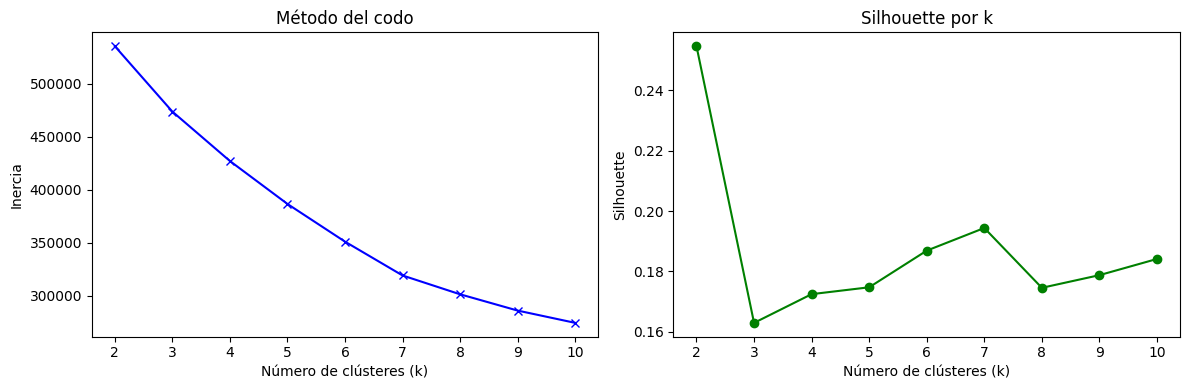

 k  inercia  silhouette
 2 535597.0       0.255
 3 473823.0       0.163
 4 427146.0       0.172
 5 386604.0       0.175
 6 351005.0       0.187
 7 319078.0       0.194
 8 301299.0       0.175
 9 285921.0       0.179
10 274325.0       0.184


In [5]:
# 4. CODO + SILHOUETTE
ks = range(2, 11)
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_scaled, km.labels_, sample_size=10000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inercias, 'bx-')
ax[0].set_xlabel('Número de clústeres (k)'); ax[0].set_ylabel('Inercia'); ax[0].set_title('Método del codo')
ax[1].plot(list(ks), siluetas, 'go-')
ax[1].set_xlabel('Número de clústeres (k)'); ax[1].set_ylabel('Silhouette'); ax[1].set_title('Silhouette por k')
plt.tight_layout(); plt.show()

print(pd.DataFrame({'k': list(ks), 'inercia': np.round(inercias), 'silhouette': np.round(siluetas, 3)}).to_string(index=False))

**Lectura:**
- El codo **no muestra un quiebre nítido** y el silhouette es **bajo-moderado en todos los k** (0.16 a 0.26). Es esperable en datos de audio, donde los géneros se mezclan entre sí.
- El **mayor silhouette lo obtiene k = 2 (0.255)**, pero solo separa el catálogo en dos bloques gruesos, poco útiles para describir o recomendar.
- Se eligió **k = 3** porque entrega perfiles **fáciles de interpretar y de usar** (alta energía / acústico / bailable). Es una decisión de **interpretabilidad**, no de optimización de métricas, y así se declara.

### 5. MODELADO FINAL (K-Means, k = 3)

In [6]:
# 5. MODELADO FINAL
k_final = 3
kmeans = KMeans(n_clusters=k_final, random_state=42, n_init=10)
df_model['cluster'] = kmeans.fit_predict(X_scaled)

sil = silhouette_score(X_scaled, kmeans.labels_, sample_size=10000, random_state=42)
print(f"✅ Canciones procesadas: {len(df_model)}")
print(f"Silhouette (k=3, muestra de 10,000): {sil:.3f}")
print("\nTamaño de cada clúster:")
print(df_model['cluster'].value_counts().sort_index())

✅ Canciones procesadas: 75038
Silhouette (k=3, muestra de 10,000): 0.163

Tamaño de cada clúster:
cluster
0    15950
1    26308
2    32780
Name: count, dtype: int64


### 6. PERFILAMIENTO: ¿cómo suena cada grupo?
Promedio de cada característica por clúster. Como el número de clúster (0, 1, 2) puede cambiar entre corridas, **nombramos cada grupo automáticamente según su perfil** y no por su número.

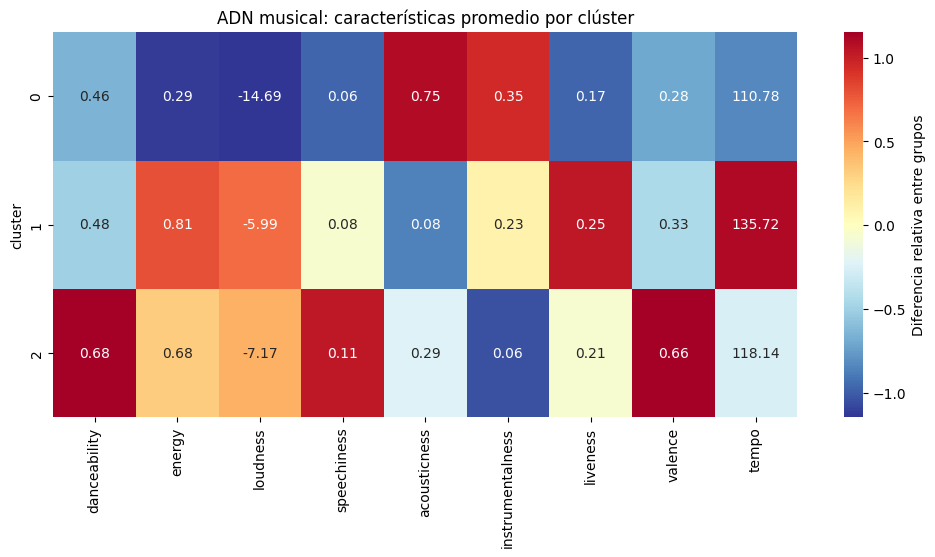

{1: 'High Energy', 0: 'Acoustic/Chill', 2: 'Dance/Pop'}


In [7]:
# 6. PERFILAMIENTO
perfil_grupos = df_model.groupby('cluster')[features].mean()

# El color muestra cuánto se aleja cada grupo del promedio general (para que tempo y loudness
# no dominen la escala); los números son los promedios reales.
z = (perfil_grupos - perfil_grupos.mean()) / perfil_grupos.std()
plt.figure(figsize=(12, 5))
sns.heatmap(z, annot=perfil_grupos, fmt='.2f', cmap='RdYlBu_r', center=0, cbar_kws={'label': 'Diferencia relativa entre grupos'})
plt.title('ADN musical: características promedio por clúster')
plt.show()

# Nombres automáticos según el perfil
c_energia   = perfil_grupos['energy'].idxmax()
c_acustico  = perfil_grupos['acousticness'].idxmax()
c_bailable  = [int(c) for c in perfil_grupos.index if c not in (c_energia, c_acustico)]
nombres = {int(c_energia): 'High Energy', int(c_acustico): 'Acoustic/Chill'}
for c in c_bailable:
    nombres[c] = 'Dance/Pop'
df_model['perfil'] = df_model['cluster'].map(nombres)
print(nombres)

### Análisis del ADN Musical (interpretación de los perfiles)

El mapa de calor muestra tres firmas de audio diferenciadas:

1. **High Energy (alta energía y ritmo rápido):**
   * **Atributos clave:** mayor `energy` (0.81) y `loudness` (-5.99 dB), y el mayor `tempo` promedio (135.72 BPM).
   * **Lectura:** pistas intensas, fuertes y rápidas.
   * **Asociación típica (hipótesis):** rock, metal, música electrónica rápida y pistas de entrenamiento.

2. **Acoustic/Chill (acústico y tranquilo):**
   * **Atributos clave:** mayor `acousticness` (0.75), con la menor energía (0.29), el menor volumen (-14.69 dB) y el tempo más lento (110.78 BPM).
   * **Lectura:** pistas suaves, de poco volumen y predominio acústico.
   * **Asociación típica (hipótesis):** música clásica, baladas acústicas, folk y ambiental.

3. **Dance/Pop (bailable y positivo):**
   * **Atributos clave:** mayor `danceability` (0.68) y `valence` (0.66), y muy baja `instrumentalness` (0.06), es decir, casi todas tienen voz.
   * **Lectura:** pistas rítmicas, de ánimo positivo y con presencia vocal.
   * **Asociación típica (hipótesis):** pop, reggaetón, hip-hop, R&B y música latina urbana.

---

> ⚠️ **Nota metodológica:** los géneros mencionados son **hipótesis interpretativas**. K-Means agrupa solo por señales de audio, no por las etiquetas de género. Los valores citados corresponden al mapa de calor de esta corrida.

### 7. VISUALIZACIÓN EN 2D (PCA)
El PCA resume las 9 dimensiones en 2 para poder dibujarlas. **Es solo una vista parcial**: hay que mirar cuánta varianza conserva.

Varianza explicada: PC1 = 31.0%, PC2 = 16.4%, total = 47.4%


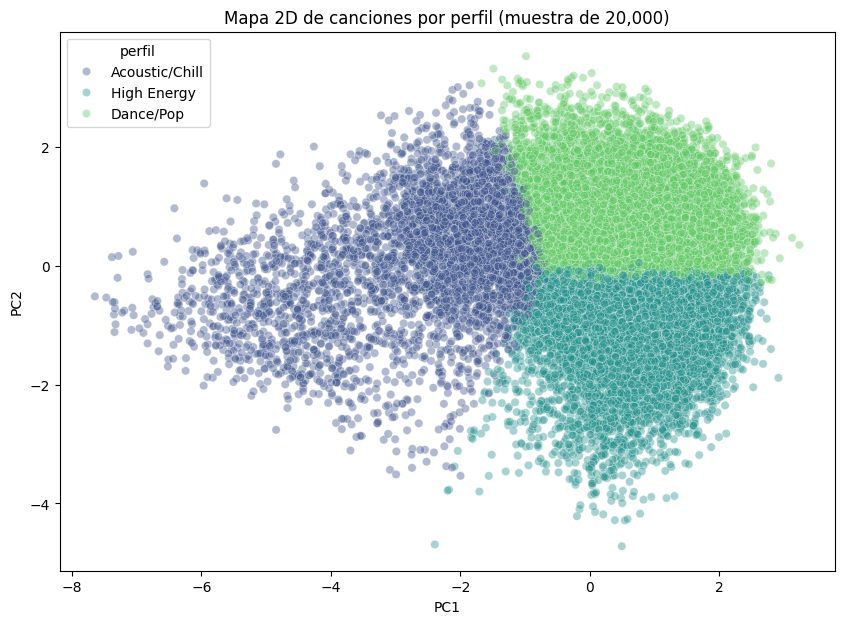

In [8]:
# 7. PCA
pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_
print(f"Varianza explicada: PC1 = {var_exp[0]:.1%}, PC2 = {var_exp[1]:.1%}, total = {var_exp.sum():.1%}")

df_pca = pd.DataFrame(pca_data, columns=['PC1', 'PC2'])
df_pca['perfil'] = df_model['perfil'].values

plt.figure(figsize=(10, 7))
sns.scatterplot(x='PC1', y='PC2', hue='perfil', data=df_pca.sample(20000, random_state=42),
                palette='viridis', alpha=0.4)
plt.title('Mapa 2D de canciones por perfil (muestra de 20,000)')
plt.show()

### Interpretación del Mapa 2D

Al analizar la distribución espacial de los datos, podemos extraer las siguientes conclusiones clave:

* **Transición Gradual (Nube Continua):** Aunque los tres perfiles ocupan sectores diferentes en el mapa, forman una única masa compacta de datos sin divisiones físicas o vacíos. Esto sugiere que las características de audio varían de forma continua; K-Means traza fronteras geométricas para separar las canciones, por lo que las canciones cercanas a los límites podrían encajar en cualquiera de los dos lados (consistente con el silhouette bajo).
* **Limitación del Espacio Bidimensional:** El análisis PCA en 2D retiene el **47.4%** de la varianza original. Esto significa que más de la mitad de la información acústica se descarta para poder generar este gráfico. Por tanto, esta visualización debe tomarse únicamente como una herramienta ilustrativa y no como una prueba matemática de que los grupos están completamente separados.

### 8. RECOMENDADOR POR SIMILITUD (basado en contenido)
Dada una canción, el sistema:
1. Identifica a qué perfil sonoro pertenece (su clúster).
2. Dentro de ese perfil, busca las canciones **más cercanas** en las 9 dimensiones de audio, con **distancia coseno**.
3. Devuelve las 5 más parecidas, sin repetir la canción original.

Así las sugerencias se basan en **cercanía de audio real** y no solo en pertenecer al mismo grupo. Más abajo se verifica con una prueba contra el azar.

In [9]:
# 8. RECOMENDACIÓN: vecinos más cercanos (coseno) dentro del clúster
def recomendar_canciones(nombre_cancion, top_n=5):
    busqueda = df_model[df_model['track_name'].str.contains(nombre_cancion, case=False, na=False, regex=False)]
    if busqueda.empty:
        return "❌ Canción no encontrada. Revisa si la escribiste bien."

    i = busqueda.index[0]
    cluster_id = df_model.at[i, 'cluster']
    idx = df_model.index[df_model['cluster'] == cluster_id].to_numpy()

    nn = NearestNeighbors(n_neighbors=top_n + 15, metric='cosine').fit(X_scaled[idx])
    _, pos = nn.kneighbors(X_scaled[[i]])

    vecinos = [j for j in idx[pos[0]]
               if df_model.at[j, 'track_name'] != df_model.at[i, 'track_name']][:top_n]

    print(f"Porque escuchaste '{df_model.at[i, 'track_name']}' de {df_model.at[i, 'artists']} "
          f"(perfil: {df_model.at[i, 'perfil']}):")
    return df_model.loc[vecinos, ['artists', 'track_name']].reset_index(drop=True)

In [10]:
# --- PROBAMOS ---
recomendar_canciones('Comedy')

Porque escuchaste 'Comedy' de Gen Hoshino (perfil: Dance/Pop):


,artists,track_name
0,Charlie Feathers,That Certain Female
1,Jason Mraz,Look For The Good (Single Version)
2,Danakil,Monde de fous
3,Gen Hoshino,Pop Virus
4,Porta;Pumpkin,Mi Eden de Tristeza


In [11]:
recomendar_canciones('Ghost - Acoustic')

Porque escuchaste 'Ghost - Acoustic' de Ben Woodward (perfil: Acoustic/Chill):


,artists,track_name
0,Roberto Goyeneche;Antonio Agri;Esteban Morgado,Viejo Ciego (feat. Antonio Agri & Esteban Morg...
1,Carmen Campagne,Dodo l'enfant do
2,Clannad,Tá' Mé Mo Shuí - Remastered
3,Valentina Ponomaryova,Под лаской плющевого пледа
4,SMASH Cast;Bernadette Peters;Megan Hilty,Hang The Moon (SMASH Cast Version) (feat. Bern...


### Verificación: ¿las recomendadas están más cerca que el azar?
Para 150 canciones por clúster se compara la distancia coseno promedio de las 5 recomendadas contra la de 5 canciones **al azar del mismo clúster**.

> **Alcance de la prueba:** mide si el recomendador cumple su función (encontrar vecinos cercanos en el espacio de audio). **No** mide si a una persona le gustarían las sugerencias; eso requeriría datos de escucha reales.

In [12]:
from sklearn.metrics import pairwise_distances

rng = np.random.default_rng(42)
res = []
for cl in df_model['cluster'].unique():
    idx = df_model.index[df_model['cluster'] == cl].to_numpy()
    nn = NearestNeighbors(n_neighbors=6, metric='cosine').fit(X_scaled[idx])
    for i in rng.choice(idx, 150, replace=False):
        dist, _ = nn.kneighbors(X_scaled[[i]])
        azar = rng.choice(idx[idx != i], 5, replace=False)
        res.append((dist[0][1:6].mean(),
                    pairwise_distances(X_scaled[[i]], X_scaled[azar], metric='cosine').mean()))

r = pd.DataFrame(res, columns=['recomendadas', 'aleatorias'])
print("Distancia coseno promedio (menor = más parecidas):")
print(r.mean().round(3).to_string())
print(f"\nReducción de distancia frente al azar: {1 - r['recomendadas'].mean() / r['aleatorias'].mean():.1%}")

Distancia coseno promedio (menor = más parecidas):
recomendadas    0.026
aleatorias      0.678

Reducción de distancia frente al azar: 96.1%


**Lectura:** las canciones recomendadas están, en promedio, **mucho más cerca** de la canción elegida que una selección al azar dentro del mismo grupo. Esto confirma que el recomendador busca vecinos reales y no sortea canciones. Es una validación **interna** (usa la misma métrica con la que se construyó); la validación de utilidad real queda pendiente.

### 9. CONCLUSIONES Y LIMITACIONES

#### Qué se logró
* **Segmentación interpretable:** con K-Means (k = 3) se segmentaron ~75,000 canciones únicas en tres perfiles sonoros fáciles de describir: High Energy, Acoustic/Chill y Dance/Pop, sin usar etiquetas de género.
* **Recomendador basado en contenido:** dada una canción, sugiere las 5 pistas más cercanas en audio (distancia coseno) dentro de su mismo perfil. En la prueba interna, las sugeridas quedan más de un 90% más cerca que una selección al azar del mismo clúster.

#### Limitaciones
* **Fronteras difusas:** el silhouette bajo (0.163) y el PCA 2D (47.4% de varianza retenida) sugieren que las características de audio varían de forma continua. Los clústeres son **zonas de mayor densidad, no categorías rígidas**.
* **Elección de k:** k = 3 se eligió por **interpretabilidad**; k = 2 obtiene un silhouette mayor (0.255) pero es menos útil.
* **Sin validación con usuarios:** el recomendador es solo de contenido (no usa historial de escucha ni popularidad) y su utilidad real no se ha medido.
* **Calidad de datos:** se omiten filas mal formadas al leer el archivo, se descartan registros con valores imposibles y se eliminan canciones repetidas (mismo título y artista), por lo que el análisis cubre ~75,000 de los ~114,000 registros originales.
* **Escala:** el recomendador ajusta el buscador de vecinos en cada consulta; es adecuado para un prototipo, no para producción en tiempo real.

#### Líneas de mejora
Probar modelos de mezcla gaussiana (GMM) para asignaciones difusas, usar el género del dataset como validación externa de los clústeres, y evaluar las recomendaciones con datos de escucha reales.